In [13]:
import matplotlib.pyplot as plt
import numpy as np
from anemone.physics import *
from numpy.linalg import solve
from numpy.linalg import det

In [14]:
from sympy import *
num_symbols = 5  # You can adjust this to the number of symbols you require
u = symbols('u1:{}'.format(num_symbols + 1))
h = symbols('h1:{}'.format(num_symbols))

a = symbols('a1:{}'.format(num_symbols))
b = symbols('b1:{}'.format(num_symbols))

u0,z,hi = symbols('u0, z, h_i')
ui,ui1 = symbols('u_i, u_{i+1}')

In [15]:
ei_d,ei_u,ei1_d,ei1_u = exp(-ui*(z+hi)),exp(ui*(z+hi)),exp(-ui1*z),exp(ui1*z)

In [16]:
bnd1 = Matrix([ei_d, ei_u, -ei1_d, -ei1_u])
m1 = Matrix([bnd1.T, bnd1.T.diff(z)])
msimp = m1.subs(z,0)

In [17]:
m1

Matrix([
[     exp(-u_i*(h_i + z)),     exp(u_i*(h_i + z)),        -exp(-u_{i+1}*z),         -exp(u_{i+1}*z)],
[-u_i*exp(-u_i*(h_i + z)), u_i*exp(u_i*(h_i + z)), u_{i+1}*exp(-u_{i+1}*z), -u_{i+1}*exp(u_{i+1}*z)]])

In [18]:
msair = m1.subs(z,0).subs(hi,0)
msair

Matrix([
[   1,   1,      -1,       -1],
[-u_i, u_i, u_{i+1}, -u_{i+1}]])

In [19]:
ampVec = Matrix([a[0], b[0], a[1], b[1]])
eqset = msair*ampVec
eq1 = Eq(eqset[0],0)
eq2 = Eq(eqset[1],0)
ans = solve([eq1,eq2],a[0],b[0])

In [20]:
ans[a[0]]

(a2*u_i + a2*u_{i+1} + b2*u_i - b2*u_{i+1})/(2*u_i)

In [21]:
ans[b[0]]

(a2*u_i - a2*u_{i+1} + b2*u_i + b2*u_{i+1})/(2*u_i)

In [22]:
ampVec = Matrix([a[0], b[0], a[1], b[1]])
eqset = msimp*ampVec
eq1 = Eq(eqset[0],0)
eq2 = Eq(eqset[1],0)
ans = solve([eq1,eq2],a[0],b[0])

In [23]:
ampVec

Matrix([
[a1],
[b1],
[a2],
[b2]])

In [24]:
ans[a[0]]

a2*exp(h_i*u_i)/2 + a2*u_{i+1}*exp(h_i*u_i)/(2*u_i) + b2*exp(h_i*u_i)/2 - b2*u_{i+1}*exp(h_i*u_i)/(2*u_i)

In [25]:
ans[b[0]]

a2*exp(-h_i*u_i)/2 - a2*u_{i+1}*exp(-h_i*u_i)/(2*u_i) + b2*exp(-h_i*u_i)/2 + b2*u_{i+1}*exp(-h_i*u_i)/(2*u_i)

In [26]:
import torch

In [28]:
from anemone import constants as c

sigma = np.array([0.02, 0.1, 0.5, 1])
thick = np.arange(1, len(sigma)+1)*5

sigma = torch.from_numpy(sigma)[:, None, None].to(torch.double)
thick = torch.from_numpy(thick)[:, None, None].to(torch.double)

thick[0] = 0.

mu = torch.ones_like(sigma)*c.mu0
epsilon = torch.ones_like(sigma)*c.epsilon0
omega = torch.logspace(1, 6, 201)[None, :, None]
wave_length=torch.logspace(-5, -1, 301)[None, None, :]
bottom_val = torch.tensor([1,0], dtype=torch.complex128)

In [29]:
%%timeit

lambda2 = wave_length**2
k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
un = torch.sqrt(lambda2 - k2)
u0 = freespace_u0(omega, wave_length)
un1 = torch.roll(un, 1, dims=0)
un1[0] = u0
un2 = un*1.

euh_p = torch.exp(un2*thick)

euh_m = 1./euh_p
unratio = 0.5*un2/un1
d_un  = 0.5-unratio
m_un  = 0.5+unratio

propmat = torch.empty(m_un.shape+(2,2), dtype=torch.complex128)


propmat[..., 0, 0] = m_un*euh_p
propmat[..., 0, 1] = d_un*euh_p
propmat[..., 1, 0] = d_un*euh_m
propmat[..., 1, 1] = m_un*euh_m
answer =   torch.zeros(u0.shape+(2,), dtype=torch.complex128)
answer[..., 0] = 0.01

for i in range(len(a)-1,-1,-1):
    answer = torch.einsum('...ij,...j->...i', propmat[i], answer)
rte1 = torch.squeeze(answer[..., 1]/answer[..., 0])

31.8 ms ± 3.18 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
from anemone import constants as c

#sigma = np.abs(50*np.random.randn(31))+0.1
sigma = 10**np.random.uniform(-2.5, 0, 16)

#rho = np.array([40, 80, 200, 100, 50])

thick = np.logspace(0.3, 1.3, len(sigma))

sigma = torch.from_numpy(sigma)[:, None, None].to(torch.double)
thick = torch.from_numpy(thick)[:, None, None].to(torch.double)

thick[0] = 0.

mu = torch.ones_like(sigma)*c.mu0
epsilon = torch.ones_like(sigma)*c.epsilon0
omega = torch.logspace(1, 6, 201)[None, :, None]
wave_length=torch.logspace(-5, -1, 301)[None, None, :]
bottom_val = torch.tensor([1,0], dtype=torch.complex128)

lambda2 = wave_length**2
k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
un = torch.sqrt(lambda2 - k2)
u0 = freespace_u0(omega, wave_length)
un1 = torch.roll(un, 1, dims=0)
un1[0] = u0
un2 = un*1.

euh_p = torch.exp(un1*thick)

euh_m   = 1./euh_p
unratio = un2/un1
d_un    = 1-unratio
m_un    = 1+unratio

propmat = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)


propmat[0, 0] = m_un*euh_p
propmat[0, 1] = d_un*euh_p
propmat[1, 0] = d_un*euh_m
propmat[1, 1] = m_un*euh_m

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
for i in range(len(sigma)-1, -1, -1):
    answer = torch.einsum('ij...,j...->i...', propmat[..., i,:,:], answer)
rte1 = torch.squeeze((answer[1])/answer[0])
# rte1 = 

rte = torch.squeeze(refl_transverse_electric(sigma, thick[1:], omega, wave_length))
print(rte1[5,5])
print(rte[5,5])

tensor(-0.9886-0.0115j, dtype=torch.complex128)
tensor(-0.9886-0.0115j, dtype=torch.complex128)


In [31]:
propmat_dsigma1 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
propmat_dsigma1[0, 0] = euh_p*(thick + thick*unratio - unratio/un1)
propmat_dsigma1[0, 1] = euh_p*(thick - thick*unratio + unratio/un1)
propmat_dsigma1[1, 0] = euh_m*(-thick + thick*unratio + unratio/un1)
propmat_dsigma1[1, 1] = euh_m*(-thick - thick*unratio - unratio/un1)

propmat_disgma2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
propmat_disgma2[0, 0] = ( unratio/un2)*euh_p
propmat_disgma2[0, 1] = (-unratio/un2)*euh_p
propmat_disgma2[1, 0] = (-unratio/un2)*euh_m
propmat_disgma2[1, 1] = (unratio/un2)*euh_m

In [35]:
def get_prop_matrices(sigma, thick):
    thick[0] = 0.

    mu = torch.ones_like(sigma)*c.mu0
    epsilon = torch.ones_like(sigma)*c.epsilon0
    omega = torch.logspace(1, 6, 201)[None, :, None]
    wave_length=torch.logspace(-5, -1, 301)[None, None, :]
    bottom_val = torch.tensor([1,0], dtype=torch.complex128)

    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, 1, dims=0)
    un1[0] = u0
    un2 = un*1.

    euh_p = torch.exp(un1*thick)

    euh_m = 1./euh_p
    unratio = 0.5*un2/un1
    d_un  = 0.5-unratio
    m_un  = 0.5+unratio

    propmat = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
    propmat[0, 0] = m_un*euh_p
    propmat[0, 1] = d_un*euh_p
    propmat[1, 0] = d_un*euh_m
    propmat[1, 1] = m_un*euh_m

    propmat_dsigma1 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
    propmat_dsigma1[0, 0] = euh_p*(thick + thick*unratio - unratio/un1)
    propmat_dsigma1[0, 1] = euh_p*(thick - thick*unratio + unratio/un1)
    propmat_dsigma1[1, 0] = euh_m*(-thick + thick*unratio + unratio/un1)
    propmat_dsigma1[1, 1] = euh_m*(-thick - thick*unratio - unratio/un1)

    propmat_dsigma2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
    propmat_dsigma2[0, 0] = ( unratio/un2)*euh_p
    propmat_dsigma2[0, 1] = (-unratio/un2)*euh_p
    propmat_dsigma2[1, 0] = (-unratio/un2)*euh_m
    propmat_dsigma2[1, 1] = ( unratio/un2)*euh_m    
    return propmat, propmat_dsigma1, propmat_dsigma2

In [47]:
from anemone import constants as c

sigma = 10**np.random.uniform(-2.5, 0, 16)
thick = np.logspace(0.3, 1.3, len(sigma))
sigma = torch.from_numpy(sigma)[:, None, None].to(torch.double)
thick = torch.from_numpy(thick)[:, None, None].to(torch.double)

propmat, ds1, ds2 = get_prop_matrices(sigma, thick)
backpropmat = propmat*1.

propmat_dsigma = torch.einsum('ij...,jk...->ik...', propmat[:,:,1:], ds1[:,:,:-1])+torch.einsum('ij...,jk...->ik...', ds2[:,:,1:], propmat[:, :, :-1])



for i in range(1,propmat.shape[2]):
    propmat[:,:,i] = torch.einsum('ij...,jk...->ik...', propmat[:,:, i-1], propmat[:,:, i])

for i in range(propmat.shape[2]-2, -1, -1):
    backpropmat[:,:,i] = torch.einsum('ij...,jk...->ik...', backpropmat[:,:, i], backpropmat[:,:, i+1])

d_rte = torch.einsum('ij...,jk...->ik...', propmat[:,:,:-2], propmat_dsigma[:, :, 1:])
d_rte = torch.einsum('ij...,jk...->ik...', d_rte, backpropmat[:,:, 2:])
d_rte = d_rte[1,0] / d_rte[0,0]


answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
answer = torch.einsum('ij...,j...->i...', propmat[:,:,-1], answer)
rte1 = torch.squeeze((answer[1])/answer[0])

print(rte1.shape)
print(d_rte.shape)

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
answer = torch.einsum('ij...,j...->i...', propmat[:,:,-1], answer)
rte2 = torch.squeeze((answer[1])/answer[0])

rte0 = torch.squeeze(refl_transverse_electric(sigma, thick[1:], omega, wave_length))

sigma2 = sigma*1.
sigma2[7,...] = 10.
rte3 = torch.squeeze(refl_transverse_electric(sigma2, thick[1:], omega, wave_length))

propmat2,ds1,ds2 = get_prop_matrices(sigma2, thick)

tmp1 = torch.einsum('ij...,jk...->ik...', propmat2[:,:, 7], propmat2[:,:, 8])
tmp1 = torch.einsum('ij...,jk...->ik...', propmat[:,:, 6], tmp1)
tmp1 = torch.einsum('ij...,jk...->ik...', tmp1, backpropmat[:,:,9])

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
answer = torch.einsum('ij...,j...->i...', tmp1, answer)
rte4 = torch.squeeze((answer[1])/answer[0])

torch.Size([201, 301])
torch.Size([14, 201, 301])


In [55]:
print(rte0[5,5])
print(rte1[5,5])
print(rte2[5,5])
print(rte3[5,5])
print(rte4[5,5])

tensor(-0.9893-0.0283j, dtype=torch.complex128)
tensor(-0.9893-0.0283j, dtype=torch.complex128)
tensor(-0.9893-0.0283j, dtype=torch.complex128)
tensor(-0.9976-0.0122j, dtype=torch.complex128)
tensor(-0.9976-0.0122j, dtype=torch.complex128)


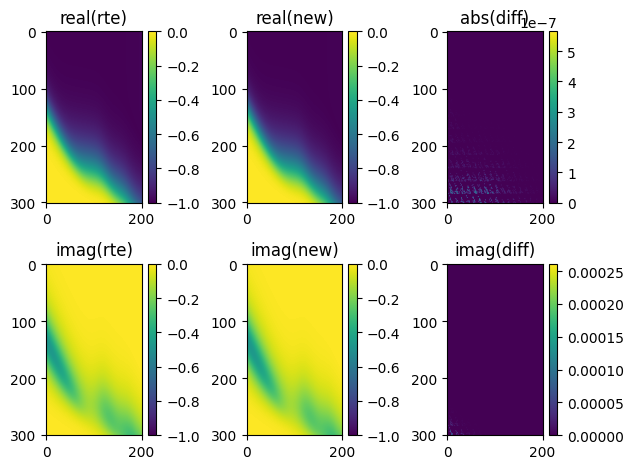

In [56]:
rte2 = rte4
rel_diff = (rte2-rte3)/rte2
fig,axs = plt.subplots(2,3)
pcm=axs[0,0].imshow(np.real(rte2).T, aspect='auto', vmin=-1, vmax=0); axs[0,0].set_title('real(rte)')
plt.colorbar(pcm, ax=axs[0,0])
pcm=axs[0,1].imshow(np.real(rte3).T, aspect='auto', vmin=-1, vmax=0); axs[0,1].set_title('real(new)')
plt.colorbar(pcm, ax=axs[0,1])
pcm=axs[0,2].imshow(np.abs(np.real(rel_diff)).T, aspect='auto'); axs[0,2].set_title('abs(diff)')
plt.colorbar(pcm, ax=axs[0,2])



pcm=axs[1,0].imshow(np.imag(rte2).T, aspect='auto', vmin=-1, vmax=0); axs[1,0].set_title('imag(rte)')
plt.colorbar(pcm, ax=axs[1,0])
pcm=axs[1,1].imshow(np.imag(rte3).T, aspect='auto', vmin=-1, vmax=0); axs[1,1].set_title('imag(new)')
plt.colorbar(pcm, ax=axs[1,1])
pcm=axs[1,2].imshow(np.abs(np.imag(rel_diff)).T, aspect='auto'); axs[1,2].set_title('imag(diff)')
plt.colorbar(pcm, ax=axs[1,2])
plt.tight_layout()

In [51]:
from anemone import constants as c

# sigma = 10**np.random.uniform(-2.5, 0, 16)



thick = np.logspace(0.3, 1.3, len(sigma))

# sigma2 = sigma2[:, None, None].to(torch.double)
thick = torch.from_numpy(thick)[:, None, None].to(torch.double)

thick[0] = 0.

mu = torch.ones_like(sigma2)*c.mu0
epsilon = torch.ones_like(sigma2)*c.epsilon0
omega = torch.logspace(1, 6, 201)[None, :, None]
wave_length=torch.logspace(-5, -1, 301)[None, None, :]
bottom_val = torch.tensor([1,0], dtype=torch.complex128)

lambda2 = wave_length**2
k2 = calc_wavenumber(sigma2, omega, mu=mu, epsilon=epsilon, sqrt=False)
un = torch.sqrt(lambda2 - k2)
u0 = freespace_u0(omega, wave_length)
un1 = torch.roll(un, 1, dims=0)
un1[0] = u0
un2 = un*1.

euh_p = torch.exp(un1*thick)

euh_m = 1./euh_p
unratio = 0.5*un2/un1
d_un  = 0.5-unratio
m_un  = 0.5+unratio

propmat2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
inv_propmat2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)

propmat2[0, 0] = m_un*euh_p
propmat2[0, 1] = d_un*euh_p
propmat2[1, 0] = d_un*euh_m
propmat2[1, 1] = m_un*euh_m

detpropmat2 = propmat2[0,0]*propmat2[1,1] - propmat2[0,1]*propmat2[1,0]
inv_propmat2[0,0] = propmat2[1,1]*1.
inv_propmat2[1,1] = propmat2[0,0]*1.
inv_propmat2[0,1] = -1.*propmat2[1,0]
inv_propmat2[1,0] = -1.*propmat2[0,1]
inv_propmat2 /= detpropmat2[None, None, ...]


calcmat2 = torch.einsum('ij...,jk...->ik...', propmat2[:,:,0], propmat2[:,:,1])
for i in range(2, propmat2.shape[2]):
    calcmat2 = torch.einsum('ij...,jk...->ik...', calcmat2, propmat2[:,:, i])

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
answer = torch.einsum('ij...,j...->i...', calcmat2, answer)
rte2 = torch.squeeze((answer[1])/answer[0])
# rte1 = 

rte = torch.squeeze(refl_transverse_electric(sigma2, thick[1:], omega, wave_length))

In [22]:
calcmat3 = torch.einsum('ij...,jk...->ik...', calcmat, inv_propmat[:, :, 7])
# calcmat3 = torch.einsum('ij...,jk...->ik...', calcmat3, inv_propmat[:, :, 6])
calcmat3 = torch.einsum('ij...,jk...->ik...', calcmat3, propmat2[:, :, 7])
# calcmat3 = torch.einsum('ij...,jk...->ik...', calcmat3, propmat2[:, :, 6])

answer =   torch.zeros((2,)+u0.shape, dtype=torch.complex128)
answer[0,:] = 1.
answer = torch.einsum('ij...,j...->i...', calcmat3, answer)
rte3 = torch.squeeze((answer[1])/answer[0])

In [23]:
print(rte2[5,5])
print(rte3[5,5])

tensor(-0.9961-0.0105j, dtype=torch.complex128)
tensor(-0.9965-0.0008j, dtype=torch.complex128)


$$ A = \left[\begin{matrix}a\;b \\ c\;d \end{matrix}\right]$$
$$A^{-1} = \frac{1}{ad-bc} \left[\begin{matrix}d\;-b \\ -c\;a \end{matrix}\right]$$

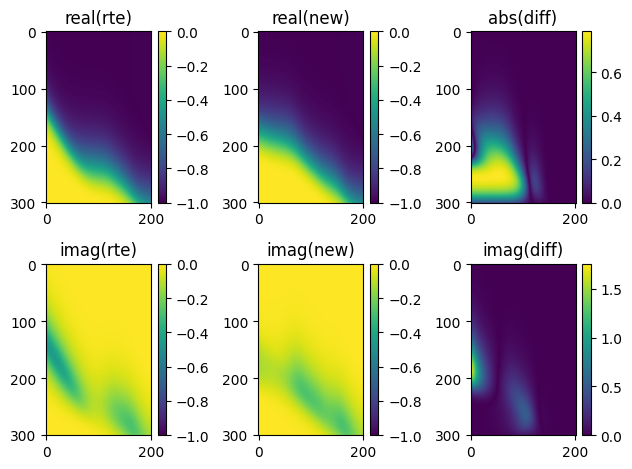

In [24]:
rel_diff = (rte2-rte3)/rte2
fig,axs = plt.subplots(2,3)
pcm=axs[0,0].imshow(np.real(rte2).T, aspect='auto', vmin=-1, vmax=0); axs[0,0].set_title('real(rte)')
plt.colorbar(pcm, ax=axs[0,0])
pcm=axs[0,1].imshow(np.real(rte3).T, aspect='auto', vmin=-1, vmax=0); axs[0,1].set_title('real(new)')
plt.colorbar(pcm, ax=axs[0,1])
pcm=axs[0,2].imshow(np.abs(np.real(rel_diff)).T, aspect='auto'); axs[0,2].set_title('abs(diff)')
plt.colorbar(pcm, ax=axs[0,2])



pcm=axs[1,0].imshow(np.imag(rte2).T, aspect='auto', vmin=-1, vmax=0); axs[1,0].set_title('imag(rte)')
plt.colorbar(pcm, ax=axs[1,0])
pcm=axs[1,1].imshow(np.imag(rte3).T, aspect='auto', vmin=-1, vmax=0); axs[1,1].set_title('imag(new)')
plt.colorbar(pcm, ax=axs[1,1])
pcm=axs[1,2].imshow(np.abs(np.imag(rel_diff)).T, aspect='auto'); axs[1,2].set_title('imag(diff)')
plt.colorbar(pcm, ax=axs[1,2])
plt.tight_layout()

In [95]:
# def prof_function():
#     lambda2 = wave_length**2
#     k2 = calc_wavenumber(sigma1, omega, mu=mu, epsilon=epsilon, sqrt=False)
#     un = torch.sqrt(lambda2 - k2)
#     u0 = freespace_u0(omega, wave_length)
#     un1 = torch.roll(un, -1)
#     un1[-1] = u0
#     un2 = un*1.

#     euh_p = torch.exp(un2*thick1)

#     euh_m = 1./euh_p
#     unratio = 0.5*un2/un1
#     d_un  = 0.5-unratio
#     m_un  = 0.5+unratio

# #Total time: 0.0088392 s
#     # propmat = torch.empty(m_un.shape+(2,2), dtype=torch.complex128)

#     # propmat[..., 0, 0] = m_un*euh_p
#     # propmat[..., 0, 1] = d_un*euh_p
#     # propmat[..., 1, 0] = d_un*euh_m
#     # propmat[..., 1, 1] = m_un*euh_m
#     # answer =   torch.zeros(u0.shape+(2,), dtype=torch.complex128)
#     # answer[..., 0] = 1.

#     # for i in range(len(a)):
#     #     answer = torch.einsum('...ij,...j->...i', propmat[i], answer)
#     # rte1 = torch.squeeze(answer[..., 1]/answer[..., 0])


# #Total time: 0.0068167 s
# Total time: 0.0091429 s

#     # a,b,c,d = m_un*euh_p, d_un*euh_p, d_un*euh_m, m_un*euh_m

#     # answer =   torch.zeros(u0.shape+(2,), dtype=torch.complex128)
#     # answer[..., 0] = 1.

#     # for i in range(len(a)):
#     #     tmp =       a[i]*answer[..., 0]+b[i]*answer[..., 1]
#     #     answer[..., 1] = c[i]*answer[..., 0]+d[i]*answer[..., 1]
#     #     answer[..., 0] = tmp

#     # #    answer = torch.einsum('...ij,...j->...i', propmat[i], answer)
#     # rte1 = torch.squeeze(answer[..., 1]/answer[..., 0])
#     a,b,c,d = m_un*euh_p, d_un*euh_p, d_un*euh_m, m_un*euh_m

#     p = torch.ones_like(u0)
#     q = torch.zeros_like(u0)
#     r = torch.zeros_like(u0)

#     r = a*p+b*q
#     q = c*p+d*q
#     p = r

#     # for i in range(len(a)):
#     #     tmp =       a[i]*answer[0]+b[i]*answer[1]
#     #     answer[1] = c[i]*answer[0]+d[i]*answer[1]
#     #     answer[0] = tmp

#     #    answer = torch.einsum('...ij,...j->...i', propmat[i], answer)
#     rte1 = torch.squeeze(q/p)

In [122]:
def prof_function():
    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    #un = wave_length + k2/(1+2*wave_length)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, -1)
    un1[-1] = u0
    un2 = un*1.

    euh_p = torch.exp(un2*thick)

    euh_m = 1./euh_p
    unratio = 0.5*un2/un1
    d_un  = 0.5-unratio
    m_un  = 0.5+unratio

    # a,b,c,d = m_un*euh_p, d_un*euh_p, d_un*euh_m, m_un*euh_m
    # answer =  torch.zeros(u0.shape+(2,), dtype=torch.complex128)
    # answer[..., 0] = 1.

    # for i in range(len(a)-1, -1, -1):
    #     tmp =       a[i]*answer[..., 0]+b[i]*answer[..., 1]
    #     answer[..., 1] = c[i]*answer[..., 0]+d[i]*answer[..., 1]
    #     answer[..., 0] = tmp


    propmat = torch.empty(m_un.shape+(2,2), dtype=torch.complex128)

    propmat[..., 0, 0] = m_un*euh_p
    propmat[..., 0, 1] = d_un*euh_p
    propmat[..., 1, 0] = d_un*euh_m
    propmat[..., 1, 1] = m_un*euh_m
    answer =   torch.zeros(u0.shape+(2,), dtype=torch.complex128)
    answer[..., 0] = 1.

    matrices = [propmat[i] for i in range(len(sigma)-1, -1, -1)]#+[answer]
    # res = torch.linalg.multi_dot(matrices)
    answer = reduce(lambda x,y: torch.squeeze(torch.einsum('...ij,...j->...i', y,x)), matrices, answer)
    rte1 = torch.squeeze(answer[..., 1]/answer[..., 0])
    return rte1

In [114]:
%lprun -f prof_function prof_function()

Timer unit: 1e-07 s

Total time: 0.0075854 s
File: C:\Users\au646858\AppData\Local\Temp\ipykernel_5500\504611129.py
Function: prof_function at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1                                           def prof_function():
     2         1       3555.0   3555.0      4.7      lambda2 = wave_length**2
     3         1       1722.0   1722.0      2.3      k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
     4         1       5370.0   5370.0      7.1      un = torch.sqrt(lambda2 - k2)
     5                                               #un = wave_length + k2/(1+2*wave_length)
     6         1       2200.0   2200.0      2.9      u0 = freespace_u0(omega, wave_length)
     7         1        801.0    801.0      1.1      un1 = torch.roll(un, 1)
     8         1        393.0    393.0      0.5      un1[-1] = u0
     9         1        746.0    746.0      1.0      un2 = un*1.
    10                                

In [130]:
def profile_function2():
    """ rte = (Y_0 - hat Y_1)/(Y_0 + hat Y_1) - W&H eq 4.19 (pg 205)
    where Y_0 is the intrinsic admittance
    and hat Y_1 is the surface or boundary admittance

    Args:
        sigma       (1d-array): conductivity of each layer
        thickness   (1d-array): thickness of each layer
        wave_length (1d-array): wave_length (lambda)
        omega       (1d-array): angular frequency
        mu             (float): _description_. Defaults to mu0.
        epsilon        (float): _description_. Defaults to epsilon0.

    Returns:
        reflection coefficients for transverse electric mode
    """

    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    adm_freespace = torch.sqrt(lambda2 - omega**2 * mu0*epsilon0 + 0j)/(1j*omega*mu0)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    zn = calc_zy(sigma, omega, mu=mu, epsilon=epsilon)[0]

    adm_intrinsic = torch.sqrt(lambda2 - k2)
    tanh_un_thick = torch.tanh(adm_intrinsic[:-1]*thick[1:])
    
    adm_intrinsic/= zn
    
    adm_boundary  = torch.empty_like(adm_intrinsic[0])
    adm_boundary = adm_intrinsic[-1]*1.
    
    for i in range(n_layers-2, -1, -1):
        adm_boundary = adm_intrinsic[i] \
                        *(adm_boundary + adm_intrinsic[i]*tanh_un_thick[i]) \
                        /(adm_intrinsic[i]  + adm_boundary*tanh_un_thick[i])

    rte = (adm_freespace - adm_boundary) / (adm_freespace + adm_boundary)
    return torch.squeeze(rte)

In [131]:
%lprun -f profile_function2 profile_function2()


Timer unit: 1e-07 s

Total time: 0.0089972 s
File: C:\Users\au646858\AppData\Local\Temp\ipykernel_5500\3921702593.py
Function: profile_function2 at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1                                           def profile_function2():
     2                                               """ rte = (Y_0 - hat Y_1)/(Y_0 + hat Y_1) - W&H eq 4.19 (pg 205)
     3                                               where Y_0 is the intrinsic admittance
     4                                               and hat Y_1 is the surface or boundary admittance
     5                                           
     6                                               Args:
     7                                                   sigma       (1d-array): conductivity of each layer
     8                                                   thickness   (1d-array): thickness of each layer
     9                                                   wave_length (1d-

In [132]:
rte1 = prof_function()
rte = profile_function2()
print(rte1.shape)
print(rte.shape)

torch.Size([20, 30])
torch.Size([20, 30])


In [133]:
print(rte1[5,5])
print(rte[5,5])

tensor(-2.0654e-07-5.7735e-07j, dtype=torch.complex128)
tensor(-0.9981-0.0017j, dtype=torch.complex128)


In [566]:
%load_ext line_profiler